# 14 — Agentes na origem, hub e fonte entre contas

Referência: [AgentCore workshops](https://github.com/awslabs/agentcore-samples/tree/main/06-workshops). Esta aula conserva o código da arquitetura anterior enquanto sua conversão está pendente.

## Arquitetura desta aula

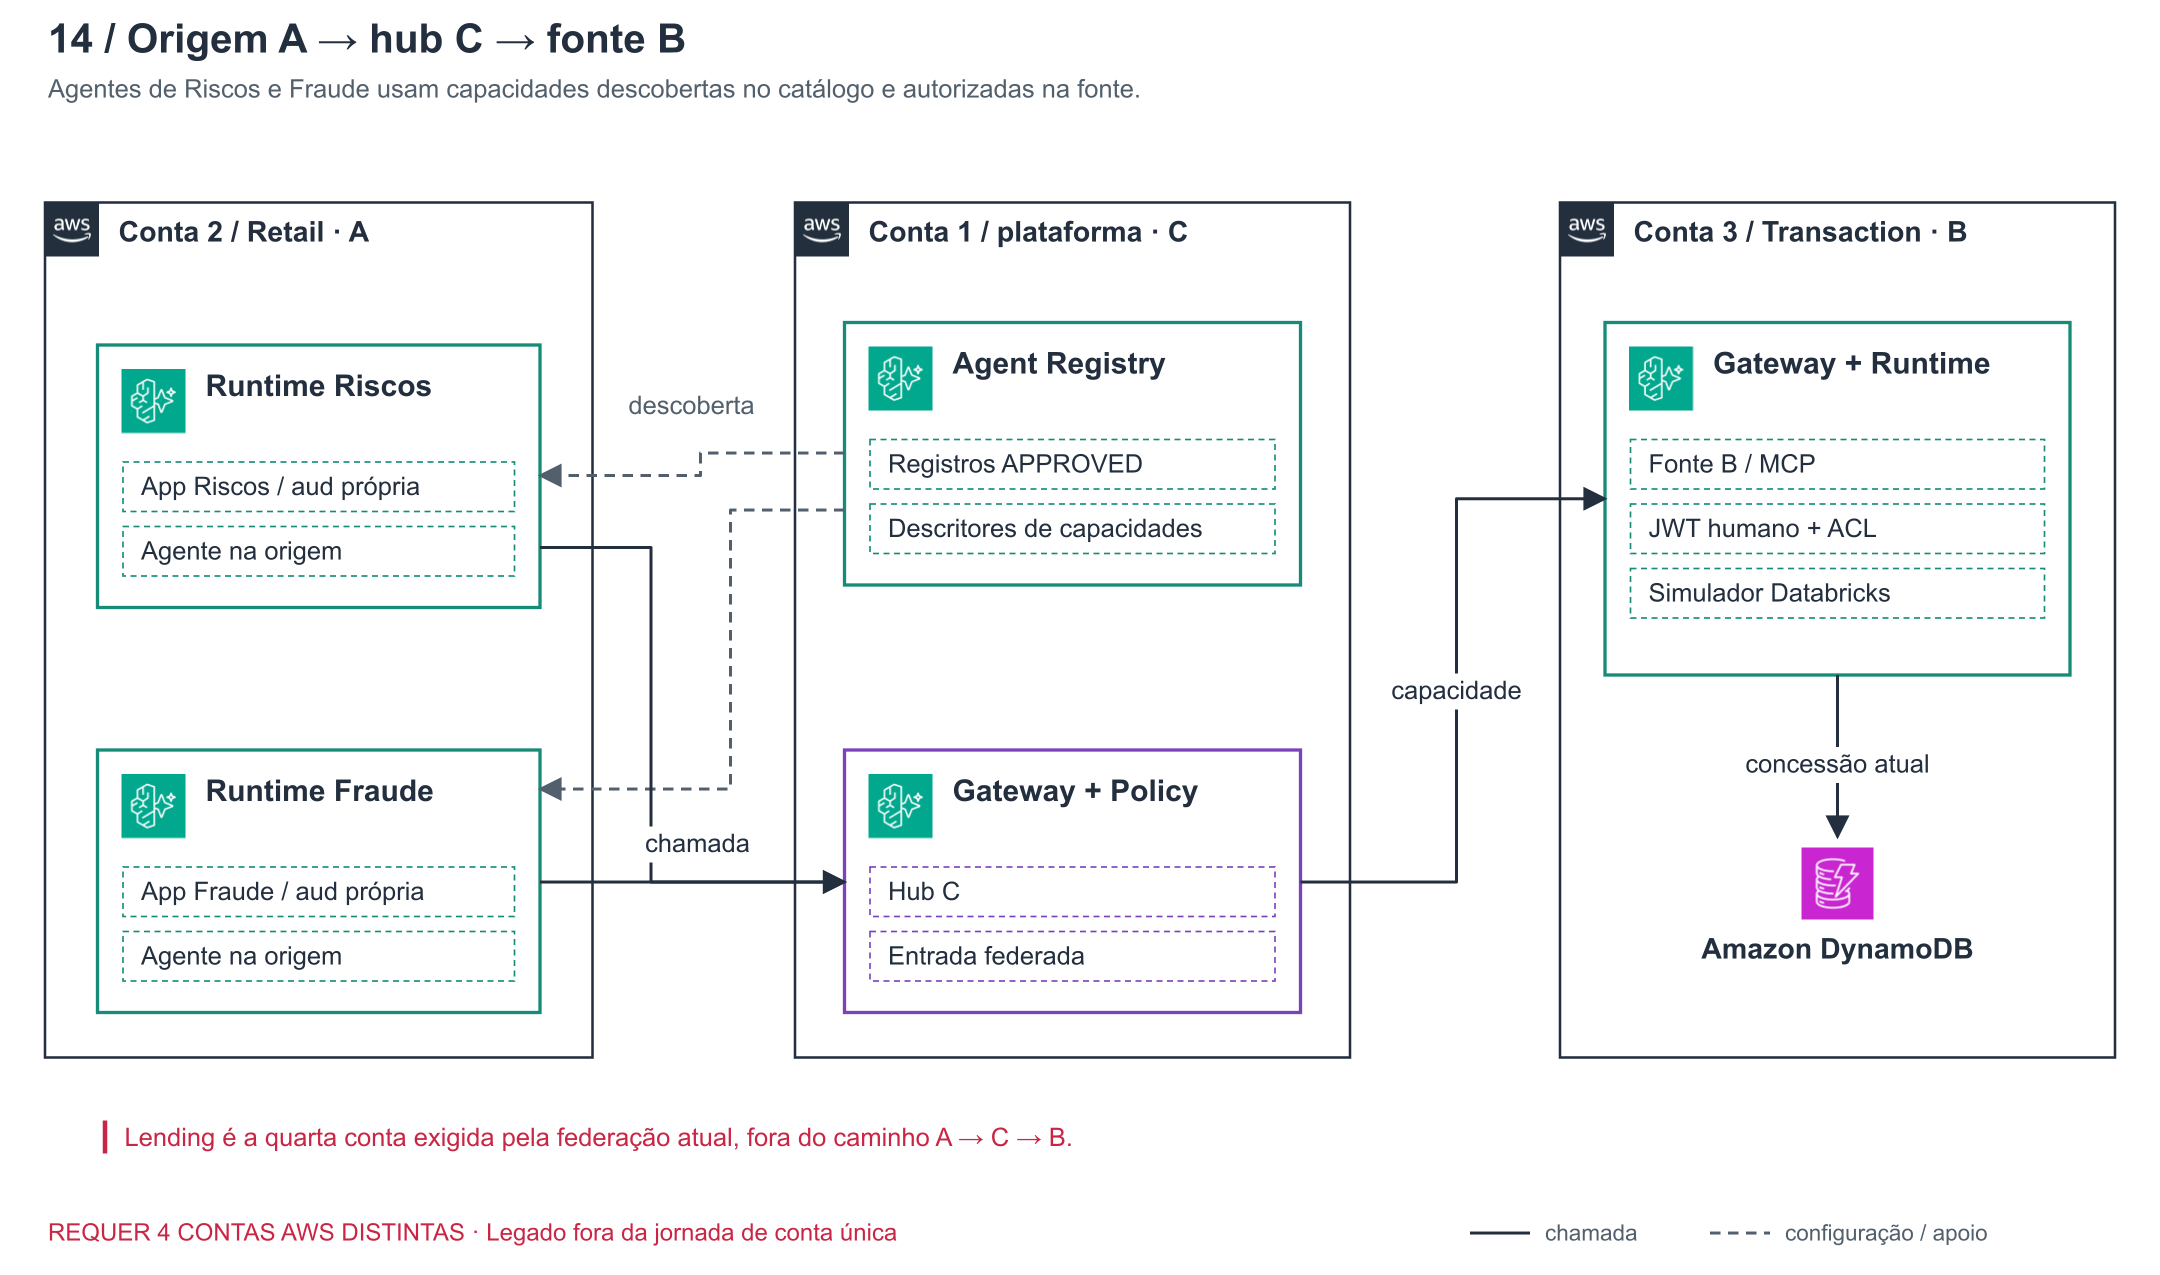

**Como ler o desenho:** Retail é a origem A; plataforma é o hub C; Transaction é a fonte B. Lending continua sendo a quarta conta requerida pelo legado. O Registry descreve capacidades; o JWT e as policies controlam as chamadas entre os componentes.

[Abrir PNG](../docs/diagramas/aulas/14.png) · [Abrir SVG](../docs/diagramas/aulas/14.svg)

## O que você vai aprender

**Pergunta da aula:** Como ligar descoberta, identidade de aplicação e execução em contas de origem, hub e fonte?

1. Relacionar registros aprovados aos agentes Riscos e Fraude.
2. Acompanhar A → C → B.
3. Testar tokens de uma aplicação no endpoint da outra.

**Estudo do legado — quatro contas AWS distintas.** Esta aula ainda depende da implantação anterior e não foi validada na jornada SDK atual. Não execute este notebook na conta única do Workshop Studio.

**Antes de começar:** Legado: quatro contas, Registry e capacidades de origem previamente publicadas e aprovadas.

**O que esta aula cria ou remove:** Nenhum recurso; descobre registros, inspeciona fases e invoca os agentes já implantados.

**O que reutiliza:** Registry, Cognito, Runtimes de origem, hub e fonte sintética da arquitetura anterior.

## Serviços AWS e suas responsabilidades

| Serviço | O que ele faz | Papel nesta aula |
|---|---|---|
| **Agent Registry** | Cataloga descritores de capacidades e controla publicação, aprovação e descoberta. Encontrar um endpoint no catálogo não concede permissão para invocá-lo. | Liga descritores aprovados aos agentes implantados. |
| **Amazon Cognito — User Pool** | Mantém usuários e aplicações e emite JWTs assinados após a autenticação. Issuer identifica o emissor, sub identifica a pessoa e aud identifica a aplicação destinatária. | Distingue as aplicações Riscos e Fraude por audiência. |
| **Amazon Bedrock AgentCore Runtime** | Hospeda código de agentes ou servidores MCP com sessão, endpoint e role de execução. A identidade que invoca o endpoint é distinta da identidade usada pelo código hospedado. | Executa os agentes na origem e o backend na fonte. |
| **Amazon Bedrock AgentCore Gateway** | Expõe ferramentas por MCP, autentica chamadas e encaminha operações aos targets. O schema informa nome, argumentos e contrato de cada ferramenta. | Intermedeia a descoberta e o acesso federado pelo hub. |
| **Amazon Bedrock AgentCore Policy** | Avalia regras Cedar sobre principal, ação, recurso e contexto de uma chamada. O engine associado ao Gateway em ENFORCE aplica suas decisões antes da ferramenta. | Aplica as decisões previstas no caminho. |
| **Amazon DynamoDB** | Armazena itens acessados por chave. Nesta demonstração, chaves de partição e condições IAM isolam as visões de dados. | Representa a fonte sintética de dados. |

**Roteiro de execução:** leia a configuração e o código, execute a célula, aguarde o estado indicado e interprete a evidência antes de avançar. As seções **Validação** destacam chamadas e asserts já presentes na aula. Um erro inesperado não equivale a uma negativa autorizada esperada.

## Pré-requisito: 4 contas AWS distintas

**Esta aula não executa em uma conta única.** O fluxo mostrado envolve 3 contas (retail-banking, platform, transaction-banking), mas o manifesto e o IaC atuais exigem as quatro contas preparadas: plataforma, Retail, Transaction e Lending. Sem elas, reserve a aula para demonstração do instrutor no ambiente completo ou retire-a da seleção de execução.

A jornada SDK atual de conta única inclui 00–09 e 15–16. Os recursos dessas aulas não preparam esta integração legada. Confira a [matriz de contas e execução](../docs/contas-e-elegibilidade.md).

Todos os serviços e agentes desta jornada são implantados na AWS.
O notebook é o roteiro e cliente das APIs; ferramentas, inferência,
políticas, fontes e memória executam nos serviços indicados.
Use o ambiente AWS descrito no [guia de implantação](../docs/deploy.md).
Configure os identificadores dos stacks antes de executar. Uma
dependência ausente bloqueia a aula antes das chamadas do exercício.
Antes de usar “Run All”, selecione as aulas compatíveis com as contas
preparadas. O bloco 10–14 exige quatro contas na implantação atual.

### Carregar a configuração e conferir as dependências

A configuração contém perfis/roles e IDs, nunca senhas ou tokens. O STS confirma a conta antes de consultar os stacks; o manifesto exige as dependências desta aula.

In [ ]:
import json
import os
import uuid
from pathlib import Path
from IPython.display import Code, display
import inspect
from santander_demo.aws_workshop.client import AWSWorkshop
from santander_demo.aws_workshop.config import load
from santander_demo.aws_workshop.manifest import require

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
CONFIG = Path(os.environ.get("WORKSHOP_CONFIG", ROOT / "config/aws.workshop.json"))
config = load(CONFIG)
dependencies = require(config, "14")
print({"lab": "14", "dependencies": list(dependencies), "region": config["region"]})

### Carregar o catálogo implantado

O catálogo tem roles diferentes para desenvolver, publicar, aprovar e consumir. Os SDKs atuais são agent-registry-control para governança e agent-registry para descoberta.

In [ ]:
from santander_demo.registry_workflow.client import RegistryLab
registry_config = json.loads((ROOT / dependencies["registry"]["config"]).read_text())
registry = RegistryLab(registry_config)
assert registry_config["RegistryArn"].startswith("arn:aws:agent-registry:")
print({"registry": registry_config["RegistryArn"], "states": registry.states()})

### Localizar as capacidades publicadas

O Registry oferece metadados aprovados. Endpoints de execução permanecem limitados aos outputs do IaC, impedindo que uma descrição de catálogo redirecione credenciais. Os registros Riscos e Fraude descrevem os dois Runtimes desta aula.

In [ ]:
from santander_demo.aws_workshop.catalog import origin_bundle, validate_origin_record
origin = AWSWorkshop(CONFIG, "retail-banking")
runtimes = {label: origin.outputs("agent-" + label.lower())["RuntimeArn"]
            for label in ["Riscos", "Fraude"]}
expected = origin_bundle(origin.identity,
                         AWSWorkshop(CONFIG).gateway["GatewayUrl"], runtimes)
records = registry.discover()
discovered = {}
reviewer = registry.persona("Approver").client("agent-registry-control")
for label in ["Riscos", "Fraude"]:
    record = next(x for x in records if x["recordId"] == registry_config[label + "RecordId"])
    assert validate_origin_record(record, expected[label]) == runtimes[label]
    state = reviewer.get_registry_record(
        registryId=registry_config["RegistryId"], recordId=record["recordId"])
    assert state["status"] == "APPROVED"
    discovered[label] = record
    display(Code(record["descriptors"]["custom"]["data"], language="json"))
print({label: value["recordId"] for label, value in discovered.items()})

### Examinar as fases de governança dessas capacidades

O pipeline workshop_catalog.py publica descriptors imutáveis, submete cada registro e aplica a decisão com seu digest revisado. Os registros dos fundamentos permanecem em seus próprios stacks.

In [ ]:
for phase in ["origin-publish", "origin-submit", "origin-approve"]:
    display(Code((ROOT / "infra/registry_workflow/templates" / (phase + ".json")).read_text(),
                 language="json"))
display(Code(inspect.getsource(validate_origin_record), language="python"))

### Executar os agentes na origem A e consultar a fonte B via hub C

Riscos e Fraude são dois Runtimes na conta Retail. Eles usam o Gateway da plataforma para chegar ao Gateway de Transaction. O Runtime da fonte verifica pessoa/aplicação e consulta a ACL.

In [ ]:
risk_token = origin.login("c", "riscos")
fraud_token = origin.login("c", "supervisor")
risk = await origin.invoke_agent(risk_token, "Consulte o risco de C001.",
                                 domain="transaction-banking", phase="agent-riscos")
fraud = await origin.invoke_agent(fraud_token, "Consulte os indícios de fraude de C001.",
                                  domain="transaction-banking", phase="agent-fraude")
assert all(x["execution"] == "AWS_AGENTCORE_RUNTIME" for x in [risk, fraud])
print(json.dumps({
    "riscos": {"registry_record_id": discovered["Riscos"]["recordId"], **risk},
    "fraude": {"registry_record_id": discovered["Fraude"]["recordId"], **fraud},
}, indent=2, ensure_ascii=False))

### Negar a audiência da outra aplicação na entrada do Runtime

Um registro aprovado não altera o authorizer. O token de Supervisor não deve entrar no Runtime de Riscos, nem o token de Riscos no de Fraude. A rejeição deve acontecer antes do agente.

### Validação — isolamento entre aplicações

A célula abaixo executa as verificações deste ponto. Compare sua saída com os critérios antes de continuar.

| Caso observado | Resultado esperado | O que comprova |
|---|---|---|
| Token Fraude no endpoint Riscos e vice-versa | HTTP 401/403 com Request ID | A entrada não aceita a audiência da outra aplicação. |

In [ ]:
import httpx
from urllib.parse import quote
denied = []
async with httpx.AsyncClient(timeout=60, follow_redirects=False) as http:
    for label, wrong_token in [("Riscos", fraud_token), ("Fraude", risk_token)]:
        endpoint = (f"https://bedrock-agentcore.{config['region']}.amazonaws.com/runtimes/"
                    + quote(runtimes[label], safe="") + "/invocations?qualifier=DEFAULT")
        response = await http.post(endpoint, headers={
            "Authorization": "Bearer " + wrong_token,
            "X-Amzn-Bedrock-AgentCore-Runtime-Session-Id": str(uuid.uuid4()),
        }, json={"question": "Consulte C001.", "domain": "transaction-banking"})
        assert response.status_code in {401, 403}
        assert response.headers.get("x-amzn-requestid")
        denied.append({"agent": label, "wrong_audience": "DENIED",
                       "runtime_request_id": response.headers["x-amzn-requestid"]})
print(denied)

### Leitura do resultado — isolamento entre aplicações

Compare com as duas execuções permitidas da célula anterior. O teste negativo cobre a entrada do Runtime; não comprova, sozinho, cada autorização dos saltos posteriores.

**Limite da demonstração:** os serviços AgentCore e as contas são reais. O backend Databricks é um simulador AWS explicitamente identificado. A aprovação no Registry, a decisão Cedar e o grant na fonte são evidências distintas.

### Evidências e encerramento

Registre IDs de requisição e decisões, sem tokens ou senhas. Os recursos são compartilhados entre aulas: a remoção pertence ao pipeline de limpeza do projeto e deve respeitar essa dependência.

## Análise dos resultados

A arquitetura conecta governança do catálogo a identidades de aplicação e serviços em contas distintas.

**Evidência e alcance:** Esta aula continua **pendente de conversão e teste no ambiente atual**. Os resultados acima são critérios esperados do código legado, não uma nova evidência de execução.

**Limites da demonstração:** Esta jornada legada continua pendente de conversão e novo teste. A fonte é sintética e não é uma integração real com Databricks; três contas no caminho não reduzem o requisito atual de quatro.

**Para discutir:** Por que um registro aprovado não torna intercambiáveis os tokens de Riscos e Fraude?

**Registro da aula:** anote conta/região, run_id quando disponível, casos permitidos/negados e IDs de requisição. Preserve a mensagem de uma falha inesperada; não publique tokens, senhas ou credenciais nas saídas. Os notebooks do repositório são distribuídos sem outputs.